# Backtests: Kupiec, Christoffersen, la prueba de duración, cuantil dinámico y el semáforo de Basilea

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema (VaR, ES y un primer conteo de excepciones)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- enunciar la hipótesis nula, el estadístico y la distribución de las pruebas de Kupiec, Christoffersen, duración y cuantil dinámico, y reproducir las dos primeras desde sus formas cerradas;
- explicar por qué el valor p binomial exacto importa cuando el número esperado de excepciones es pequeño, y mostrarlo en una ventana de 250 días al nivel de 1 por ciento;
- leer el semáforo de Basilea como una probabilidad binomial acumulada, y calcular sus zonas y multiplicadores;
- volver a correr toda la batería de excepciones sobre las banderas de una ventana versionada y obtener las filas versionadas, incluidos los valores p de Monte Carlo;
- decir cuáles pruebas detectan un conteo equivocado y cuáles detectan excepciones agrupadas, a partir de los resultados versionados de las ventanas de crisis.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import special, stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Los valores de luz del motor, con las palabras que imprime este cuaderno
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C11 tal como Contraste lo versiona: cuatro ventanas del backtest de riesgo de mercado, cada una con la trayectoria del VaR, los días de excepción y las filas de pruebas versionadas de 17 modelos en los niveles de cola 1 y 2,5 por ciento.

- `calm-2004-06`: tres años tranquilos, 750 días de pronóstico (la ventana de control).
- `equity-2007-09`: la crisis financiera, 504 días.
- `equity-2020`: la caída por la pandemia, 104 días.
- `rates-2022`: el ciclo de alzas, una posición en el bono del Tesoro a 10 años, 249 días.

Las cuatro guardan los días en que la pérdida superó al VaR, que es todo lo que leen las pruebas de excepciones. Las pruebas usan **banderas** (1 en un día de excepción), así que el cuaderno reconstruye las banderas desde los días guardados y la trayectoria del VaR desde el archivo versionado. Las filas `tests` versionadas se calcularon con un motor más antiguo que el instalado; el cuaderno imprime ambas versiones y compara cada recálculo con la fila versionada. La celda siguiente carga las ventanas y define la única función auxiliar del cuaderno.

In [2]:
# Cargar las cuatro ventanas y definir la función auxiliar que reconstruye las banderas de excepción y la fila versionada de un modelo y nivel
ROOT = Path("../../..").resolve()
WINDOWS = ("calm-2004-06", "equity-2007-09", "equity-2020", "rates-2022")
windows = {w: json.loads((ROOT / "data" / "derived" / "C11" / f"{w}.json").read_text(encoding="utf-8")) for w in WINDOWS}


def series_of(window, model_id, alpha):
    """Las banderas de excepción, la trayectoria del VaR (pérdidas) y las filas versionadas de un modelo en un nivel de cola."""
    doc = windows[window]
    model = {m["model_id"]: m for m in doc["outputs"]["models"]}[model_id]
    level = [lv for lv in model["by_level"] if lv["alpha"] == alpha][0]
    flags = np.zeros(level["n_scored"], dtype=bool)
    flags[level["exceedance_days"]] = True
    rows = {t["test_id"]: t for t in doc["tests"] if t["model_id"] == model_id and t["segment"] == f"alpha={alpha:g}"}
    return flags, np.array(level["var"]), rows


print("filas versionadas calculadas por riskvalidation", windows["equity-2007-09"]["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
for w in WINDOWS:
    flags, var, rows = series_of(w, "hs-250", 0.01)
    print(f"{w:15s} días {flags.size:4d} | excepciones de hs-250 al 1%: {int(flags.sum()):3d} | esperadas {0.01 * flags.size:5.2f} | pruebas versionadas por modelo y nivel: {len(rows)}")

filas versionadas calculadas por riskvalidation 0.7.0 | instalado 0.9.0
calm-2004-06    días  750 | excepciones de hs-250 al 1%:   9 | esperadas  7.50 | pruebas versionadas por modelo y nivel: 6
equity-2007-09  días  504 | excepciones de hs-250 al 1%:  19 | esperadas  5.04 | pruebas versionadas por modelo y nivel: 6
equity-2020     días  104 | excepciones de hs-250 al 1%:   8 | esperadas  1.04 | pruebas versionadas por modelo y nivel: 6
rates-2022      días  249 | excepciones de hs-250 al 1%:   8 | esperadas  2.49 | pruebas versionadas por modelo y nivel: 6


## Método

### Paso 1: la proporción de fallas de Kupiec

Si el VaR es correcto, el indicador de excepción $I_t$ es una secuencia de variables Bernoulli($\alpha$) independientes, de modo que $x = \sum_t I_t$ en $T$ días es binomial($T$, $\alpha$). Kupiec (1995) contrasta $H_0: \Pr(I_t = 1) = \alpha$ con la razón de verosimilitud de la proporción observada $\hat\pi = x/T$ frente a $\alpha$, con la convención $0\ln 0 = 0$:

$$LR_{POF} = -2\ln\frac{(1-\alpha)^{T-x}\,\alpha^{x}}{(1-\hat\pi)^{T-x}\,\hat\pi^{x}} \;\xrightarrow{d}\; \chi^2_1$$

La función `kupiec_pof` del motor devuelve el estadístico, el valor p asintótico y, en `metric`, el valor p binomial exacto: la probabilidad total, bajo binomial($T$, $\alpha$), de los conteos que son a lo sumo tan probables como el $x$ observado. La celda calcula ambos a mano desde las definiciones, para `hs-250` en la crisis, y los compara con el motor y con la fila versionada.

In [3]:
# Kupiec a mano desde la definición (estadístico, p asintótico, p exacto), frente al motor y a la fila versionada
from riskvalidation.validation.market import kupiec_pof

alpha = 0.01
flags, var, rows = series_of("equity-2007-09", "hs-250", alpha)
T, x = flags.size, int(flags.sum())
pi_hat = x / T
lr = -2.0 * ((T - x) * math.log(1 - alpha) + special.xlogy(x, alpha) - (T - x) * math.log(1 - pi_hat) - special.xlogy(x, pi_hat))
p_asymptotic = stats.chi2.sf(lr, 1)
pmf = stats.binom.pmf(np.arange(T + 1), T, alpha)
p_exact = pmf[pmf <= pmf[x] * (1 + 1e-7)].sum()
print(f"T {T}, x {x}, esperadas {alpha * T:.2f}, proporción observada {pi_hat:.4f}")
print(f"a mano   : LR {lr:.4f} | p asintótico {p_asymptotic:.3e} | p exacto {p_exact:.3e}")

engine = kupiec_pof(flags, alpha, model_id="hs-250")
row = rows["market.kupiec_pof"]
print(f"motor    : LR {engine.statistic:.4f} | p asintótico {engine.p_value:.3e} | p exacto {engine.metric:.3e} | luz {LIGHT[engine.light.value]}")
print(f"versionado: LR {row['statistic']:.4f} | p asintótico {row['p_value']:.3e} | p exacto {row['metric']:.3e} | luz {LIGHT[row['light']]}")

T 504, x 19, esperadas 5.04, proporción observada 0.0377
a mano   : LR 22.9015 | p asintótico 1.705e-06 | p exacto 1.303e-06
motor    : LR 22.9015 | p asintótico 1.705e-06 | p exacto 1.303e-06 | luz rojo
versionado: LR 22.9015 | p asintótico 1.705e-06 | p exacto 1.303e-06 | luz rojo


### Paso 2: cuando el conteo esperado es pequeño

En una ventana de 250 días al nivel de 1 por ciento el conteo esperado es 2,5. La ley chi-cuadrado es entonces una mala aproximación de un estadístico discreto que solo puede tomar pocos valores, y los valores p asintótico y exacto pueden quedar a lados opuestos de un umbral. La celda siguiente construye una serie de 250 banderas con $x$ excepciones para $x = 0,\dots,10$ e imprime ambos valores p, con la luz que les da la compuerta de Contraste (ámbar bajo 0,10, roja bajo 0,05). La compuerta es una convención interna, no un umbral regulatorio.

In [4]:
# Valor p asintótico frente al exacto para cada conteo de 0 a 10 en una ventana de 250 días al nivel de 1%
print(f"{'x':>3s} {'p asintótico':>13s} {'p exacto':>9s}  luz según el p asintótico")
for count in range(0, 11):
    series = np.zeros(250, dtype=bool)
    series[:count] = True                               # la posición de las banderas no importa a esta prueba
    result = kupiec_pof(series, 0.01)
    print(f"{count:3d} {result.p_value:13.4f} {result.metric:9.4f}  {LIGHT[result.light.value]}")

  x  p asintótico  p exacto  luz según el p asintótico
  0        0.0250    0.1889  rojo
  1        0.2781    0.5276  verde
  2        0.7419    1.0000  verde
  3        0.7580    0.7426  verde
  4        0.3805    0.3229  verde
  5        0.1619    0.1078  verde
  6        0.0594    0.0412  ámbar
  7        0.0190    0.0137  rojo
  8        0.0054    0.0040  rojo
  9        0.0014    0.0011  rojo
 10        0.0003    0.0003  rojo


### Paso 3: la independencia y la cobertura condicional de Christoffersen

Un modelo puede tener el número correcto de excepciones y aun así estar equivocado si llegan en racimos. Christoffersen (1998) contrasta la secuencia de excepciones contra una cadena de Markov de primer orden. Sea $n_{ij}$ el número de días en que el estado $i$ fue seguido por el estado $j$ ($0$ sin excepción, $1$ excepción), $\pi_{01} = n_{01}/(n_{00}+n_{01})$, $\pi_{11} = n_{11}/(n_{10}+n_{11})$ y $\pi = (n_{01}+n_{11})/(n_{00}+n_{01}+n_{10}+n_{11})$:

$$LR_{ind} = -2\ln\frac{(1-\pi)^{n_{00}+n_{10}}\,\pi^{n_{01}+n_{11}}}{(1-\pi_{01})^{n_{00}}\,\pi_{01}^{n_{01}}\,(1-\pi_{11})^{n_{10}}\,\pi_{11}^{n_{11}}} \xrightarrow{d} \chi^2_1, \qquad LR_{cc} = LR_{POF} + LR_{ind} \xrightarrow{d} \chi^2_2$$

La independencia se cumple cuando $\pi_{01} = \pi_{11}$: una excepción no cambia la probabilidad de otra mañana. La celda cuenta las transiciones de las banderas de `garch-t` en la crisis al 2,5 por ciento, calcula los estadísticos a mano y los compara con `christoffersen_independence` y `christoffersen_conditional_coverage`.

In [5]:
# Conteos de transiciones y estadísticos de Christoffersen a mano, frente al motor y a las filas versionadas
from riskvalidation.validation.market import christoffersen_conditional_coverage, christoffersen_independence

alpha = 0.025
flags, var, rows = series_of("equity-2007-09", "garch-t", alpha)
before, after = flags[:-1], flags[1:]
n00, n01 = int(np.sum(~before & ~after)), int(np.sum(~before & after))
n10, n11 = int(np.sum(before & ~after)), int(np.sum(before & after))
pi01, pi11 = n01 / (n00 + n01), n11 / (n10 + n11)
pi = (n01 + n11) / (n00 + n01 + n10 + n11)
print(f"transiciones: n00 {n00}, n01 {n01}, n10 {n10}, n11 {n11}")
print(f"P(excepción | ninguna ayer) {pi01:.4f} | P(excepción | excepción ayer) {pi11:.4f} | incondicional {pi:.4f}")

null = special.xlogy(n00 + n10, 1 - pi) + special.xlogy(n01 + n11, pi)
alternative = (special.xlogy(n00, 1 - pi01) + special.xlogy(n01, pi01) + special.xlogy(n10, 1 - pi11) + special.xlogy(n11, pi11))
lr_ind = -2.0 * (null - alternative)
print(f"a mano: LR_ind {lr_ind:.4f} | p {stats.chi2.sf(lr_ind, 1):.4f}")

ind = christoffersen_independence(flags, alpha, model_id="garch-t")
cc = christoffersen_conditional_coverage(flags, alpha, model_id="garch-t")
for label, result, key in (("independencia", ind, "market.christoffersen_independence"), ("cobertura condicional", cc, "market.christoffersen_conditional_coverage")):
    print(f"{label:21s}: motor LR {result.statistic:.4f} p {result.p_value:.4f} {LIGHT[result.light.value]} | "
          f"versionado LR {rows[key]['statistic']:.4f} p {rows[key]['p_value']:.4f} {LIGHT[rows[key]['light']]}")
print(f"LR_cc = LR_POF + LR_ind: {cc.extras['lr_pof']:.4f} + {cc.extras['lr_ind']:.4f} = {cc.statistic:.4f}")

transiciones: n00 441, n01 31, n10 31, n11 0
P(excepción | ninguna ayer) 0.0657 | P(excepción | excepción ayer) 0.0000 | incondicional 0.0616
a mano: LR_ind 4.0750 | p 0.0435
independencia        : motor LR 4.0750 p 0.0435 rojo | versionado LR 4.0750 p 0.0435 rojo
cobertura condicional: motor LR 23.7907 p 0.0000 rojo | versionado LR 23.7907 p 0.0000 rojo
LR_cc = LR_POF + LR_ind: 19.7157 + 4.0750 = 23.7907


### Paso 4: la prueba de duración

La prueba de independencia mira solo un día hacia adelante. Christoffersen y Pelletier (2004) miran las **duraciones** $D_i$, los días entre excepciones consecutivas. Si la cobertura es correcta y las excepciones son independientes, las duraciones no tienen memoria (geométricas, cercanas a la exponencial), y la probabilidad de una excepción no depende del tiempo desde la última. Modelan el riesgo instantáneo como Weibull, $\lambda(d) = a^b\,b\,d^{\,b-1}$, con $b = 1$ bajo la nula, de modo que $b < 1$ es un riesgo decreciente (agrupamiento) y $b > 1$ uno creciente (demasiado regular). El estadístico es la razón de verosimilitud de $b = 1$, con el primer y el último tramo censurados, y su valor p es por Monte Carlo (sorteos de secuencias Bernoulli($\alpha$) del mismo largo). La forma Weibull es la estándar en la literatura; el motor documenta que no se re-verificó contra el texto completo del artículo.

La celda lista las duraciones completas de `hs-250` en la crisis al 1 por ciento, ejecuta `duration_test` con el número de sorteos y la semilla versionados y compara con la fila versionada. Las mismas entradas y la misma semilla dan el mismo valor p.

In [6]:
# Duraciones entre excepciones, y luego la prueba de duración con los sorteos y la semilla versionados frente a la fila versionada
from riskvalidation.validation.market import duration_test

alpha = 0.01
flags, var, rows = series_of("equity-2007-09", "hs-250", alpha)
days = np.flatnonzero(flags)
durations = np.diff(days)
print(f"excepciones {days.size} | duraciones completas {durations.size} | media {durations.mean():.1f} días | esperada bajo la nula {1 / alpha:.0f}")
print("duraciones:", durations.tolist())

row = rows["market.duration_test"]
engine = duration_test(flags, alpha, model_id="hs-250", n_mc=10000, seed=42)
print(f"motor    : LR {engine.statistic:.4f} | b de Weibull {engine.extras['weibull_b']:.3f} | p {engine.p_value:.4f} | luz {LIGHT[engine.light.value]}")
print(f"versionado: LR {row['statistic']:.4f} | b de Weibull {row['extras']['weibull_b']:.3f} | p {row['p_value']:.4f} | luz {LIGHT[row['light']]}")

excepciones 19 | duraciones completas 18 | media 19.1 días | esperada bajo la nula 100
duraciones: [2, 6, 4, 63, 48, 12, 85, 14, 48, 3, 4, 2, 3, 5, 6, 2, 4, 32]
motor    : LR 5.1768 | b de Weibull 0.690 | p 0.0824 | luz ámbar
versionado: LR 5.1768 | b de Weibull 0.690 | p 0.0824 | luz ámbar


### Paso 5: la prueba de cuantil dinámico

Engle y Manganelli (2004) preguntan si las excepciones son **predecibles** a partir de algo conocido el día anterior. Se regresa el acierto demediado $\mathrm{Hit}_t = I_t - \alpha$ sobre una constante, cuatro aciertos rezagados y el VaR actual, reunidos en la matriz $X$. Bajo cobertura condicional correcta ningún coeficiente difiere de cero, y la forma cuadrática

$$DQ = \frac{\mathrm{Hit}^{\top} X\,(X^{\top}X)^{+}\,X^{\top}\mathrm{Hit}}{\alpha(1-\alpha)}$$

es asintóticamente chi-cuadrado con grados de libertad iguales al rango de $X$. Con aciertos escasos esa ley es mala: el motor registra que la prueba simple rechazó pronósticos correctos mucho más que el 5 por ciento, así que su luz sigue un **valor p de Monte Carlo** y el asintótico queda en `extras`. La celda calcula la forma cuadrática a mano desde la definición sobre las banderas de `hs-250` y la compara con el estadístico y los valores p del motor.

In [7]:
# La forma cuadrática DQ a mano (4 rezagos), frente al estadístico del motor, sus dos valores p y la fila versionada
from riskvalidation.validation.market import dynamic_quantile_test

lags = 4
hits = flags.astype(float)
X = np.column_stack([np.ones(hits.size - lags)] + [hits[lags - j:hits.size - j] for j in range(1, lags + 1)] + [var[lags:]])
hit_demeaned = hits[lags:] - alpha
dq_by_hand = float(hit_demeaned @ X @ np.linalg.pinv(X.T @ X) @ X.T @ hit_demeaned) / (alpha * (1 - alpha))
print(f"regresión: {X.shape[0]} días, {X.shape[1]} columnas (constante, {lags} rezagos, VaR), rango {np.linalg.matrix_rank(X)}")
print(f"a mano: DQ {dq_by_hand:.4f}")

row = rows["market.dynamic_quantile_test"]
engine = dynamic_quantile_test(flags, var, alpha, lags=lags, model_id="hs-250", n_mc=10000, seed=42)
print(f"motor    : DQ {engine.statistic:.4f} | p de Monte Carlo {engine.p_value:.4f} | p asintótico {engine.extras['p_value_asymptotic']:.4f} | luz {LIGHT[engine.light.value]}")
print(f"versionado: DQ {row['statistic']:.4f} | p de Monte Carlo {row['p_value']:.4f} | p asintótico {row['extras']['p_value_asymptotic']:.4f} | luz {LIGHT[row['light']]}")

regresión: 500 días, 6 columnas (constante, 4 rezagos, VaR), rango 6
a mano: DQ 121.1612
motor    : DQ 121.1612 | p de Monte Carlo 0.0003 | p asintótico 0.0000 | luz rojo
versionado: DQ 121.1612 | p de Monte Carlo 0.0003 | p asintótico 0.0000 | luz rojo


### Paso 6: el semáforo de Basilea

El marco de Basilea de 1996 juzga el VaR al 99 por ciento de un banco por el número de excepciones $k$ en los últimos 250 días hábiles. Bajo un modelo correcto $k \sim$ binomial(250; 0,01), y las zonas se cortan sobre la probabilidad acumulada $P(X \le k)$: **verde** bajo el conteo en que primero llega a 95 por ciento, **ámbar** desde ahí, **roja** desde el conteo en que llega a 99,99 por ciento. El multiplicador $m_c$ del cargo de capital sube con la zona (MAR32.9, Tabla 1). El motor tiene las tres piezas como funciones: `binomial_cumulative_probability`, `traffic_light_zone` y `mar32_multiplier`; la celda las imprime para 0 a 12 excepciones. El multiplicador impreso es el multiplicador dependiente del backtesting $m_c$ de MAR32.9, de 1,50 a 2,00; el documento de la escalera versionado lista a su lado el factor estadounidense más antiguo, de 3,00 a 4,00.

In [8]:
# La tabla del semáforo: probabilidad acumulada, zona y multiplicador para 0 a 12 excepciones en 250 días con cobertura de 99%
from riskvalidation.market.frtb import binomial_cumulative_probability, mar32_multiplier, traffic_light_zone

print(f"{'excepciones':>11s} {'P(X <= k)':>10s}  {'zona':6s} {'multiplicador':>13s}")
for k in range(0, 13):
    probability = binomial_cumulative_probability(k, 250, 0.01)
    print(f"{k:11d} {100 * probability:9.4f}%  {LIGHT[traffic_light_zone(k)]:6s} {mar32_multiplier(k):13.2f}")

excepciones  P(X <= k)  zona   multiplicador
          0    8.1059%  verde           1.50
          1   28.5752%  verde           1.50
          2   54.3169%  verde           1.50
          3   75.8117%  verde           1.50
          4   89.2188%  verde           1.50
          5   95.8817%  ámbar           1.70
          6   98.6299%  ámbar           1.76
          7   99.5975%  ámbar           1.83
          8   99.8943%  ámbar           1.88
          9   99.9750%  ámbar           1.92
         10   99.9946%  rojo            2.00
         11   99.9989%  rojo            2.00
         12   99.9998%  rojo            2.00


El semáforo es función de los últimos 250 días, así que sobre una ventana más larga se puede calcular en cada ventana móvil. El artefacto versionado guarda, para cada modelo, cuántas de las ventanas móviles fueron verdes, ámbar y rojas. La celda siguiente recalcula la zona del conteo móvil de 250 días para `hs-250` y `ewma` en la crisis, y compara el recuento y la zona final con el bloque `traffic_light` versionado y con `basel_traffic_light` del motor sobre los últimos 250 días.

In [9]:
# Conteos móviles de excepciones de 250 días y sus zonas, frente al recuento versionado y a la luz del motor sobre los últimos 250 días
from riskvalidation.validation.market import basel_traffic_light

rolling = {}
for model_id in ("hs-250", "ewma"):
    flags, var, rows = series_of("equity-2007-09", model_id, 0.01)
    running = np.concatenate([[0], np.cumsum(flags)])
    counts = (running[250:] - running[:-250]).astype(int)           # excepciones en cada ventana de 250 días
    zones = [traffic_light_zone(int(k)) for k in counts]
    tally = {z: zones.count(z) for z in ("green", "amber", "red")}
    committed = [m for m in windows["equity-2007-09"]["outputs"]["models"] if m["model_id"] == model_id][0]["by_level"][0]["traffic_light"]
    light = basel_traffic_light(flags, model_id=model_id)
    rolling[model_id] = counts
    print(f"{model_id}: {counts.size} ventanas | máximo {counts.max()} excepciones | recuento {tally}")
    print(f"  versionado: verde {committed['days_green']}, ámbar {committed['days_amber']}, rojo {committed['days_red']}, máximo {committed['max_rolling_exceedances']}")
    print(f"  última ventana: {int(light.statistic)} excepciones, probabilidad acumulada {light.metric:.4f}%, zona {LIGHT[light.light.value]}, multiplicador {light.extras['mar32_multiplier']}")

hs-250: 255 ventanas | máximo 14 excepciones | recuento {'green': 0, 'amber': 60, 'red': 195}
  versionado: verde 0, ámbar 60, rojo 195, máximo 14
  última ventana: 10 excepciones, probabilidad acumulada 99.9946%, zona rojo, multiplicador 2.0
ewma: 255 ventanas | máximo 12 excepciones | recuento {'green': 0, 'amber': 229, 'red': 26}
  versionado: verde 0, ámbar 229, rojo 26, máximo 12
  última ventana: 7 excepciones, probabilidad acumulada 99.5975%, zona ámbar, multiplicador 1.83


### Paso 7: toda la batería frente a las filas versionadas

Las funciones del motor son deterministas para una semilla fija, así que las filas `tests` versionadas deben volver exactamente desde las banderas y la trayectoria del VaR. La celda vuelve a correr Kupiec, independencia, cobertura condicional, duración (10.000 sorteos, semilla 42) y cuantil dinámico (4 rezagos, 10.000 sorteos, semilla 42) para `hs-250`, en ambos niveles, en las tres ventanas de crisis, e informa la mayor diferencia entre un estadístico o valor p recalculado y uno versionado. Una prueba que el motor no puede evaluar (menos de dos excepciones para la prueba de duración) se versiona como `not_evaluated`, y la comparación verifica que lo siga siendo.

In [10]:
# Volver a correr las cinco pruebas de excepciones en cada ventana, modelo y nivel de la muestra y compararlas con su fila versionada
compared, peor, not_evaluated, mismatches = 0, 0.0, 0, 0
for window in ("equity-2007-09", "equity-2020", "rates-2022"):
    for model_id in ("hs-250",):
        for alpha in (0.01, 0.025):
            flags, var, rows = series_of(window, model_id, alpha)
            fresh = {
                "market.kupiec_pof": kupiec_pof(flags, alpha, model_id),
                "market.christoffersen_independence": christoffersen_independence(flags, alpha, model_id),
                "market.christoffersen_conditional_coverage": christoffersen_conditional_coverage(flags, alpha, model_id),
                "market.duration_test": duration_test(flags, alpha, model_id, n_mc=10000, seed=42),
                "market.dynamic_quantile_test": dynamic_quantile_test(flags, var, alpha, lags=4, model_id=model_id, n_mc=10000, seed=42),
            }
            for test_id, result in fresh.items():
                row = rows[test_id]
                if row["light"] == "not_evaluated" or result.light.value == "not_evaluated":
                    not_evaluated += 1
                    mismatches += row["light"] != result.light.value
                    continue
                compared += 1
                peor = max(peor, abs(result.p_value - row["p_value"]), abs(result.statistic - row["statistic"]))
                mismatches += row["light"] != result.light.value
print(f"filas comparadas {compared} | no evaluadas en ambos lados {not_evaluated} | mayor diferencia {peor:.2e} | luces que difieren {mismatches}")

filas comparadas 30 | no evaluadas en ambos lados 0 | mayor diferencia 5.00e-07 | luces que difieren 0


### Paso 8: qué ve cada prueba

Un conteo equivocado y excepciones agrupadas son fallas distintas, y la batería las separa. La celda lee las filas versionadas de los 17 modelos en las tres ventanas de crisis y cuenta, en cada nivel, cuántos modelos están en rojo en la prueba de cobertura (Kupiec), en la de independencia y en la de duración. Luego dibuja las excepciones de `hs-250` y `ewma` en 2007 a 2009 sobre un eje de tiempo, con el conteo móvil de 250 días frente a los límites de zona: la región roja empieza en 10 excepciones.

ventana          nivel  cobertura (Kupiec)       independencia            duración   modelos
equity-2007-09   0.010                  17                   0                   2   17
equity-2007-09   0.025                  17                   4                   4   17
equity-2020      0.010                  12                   0                   2   17
equity-2020      0.025                  11                   0                   0   17
rates-2022       0.010                   7                   0                   1   17
rates-2022       0.025                  12                   0                   3   17


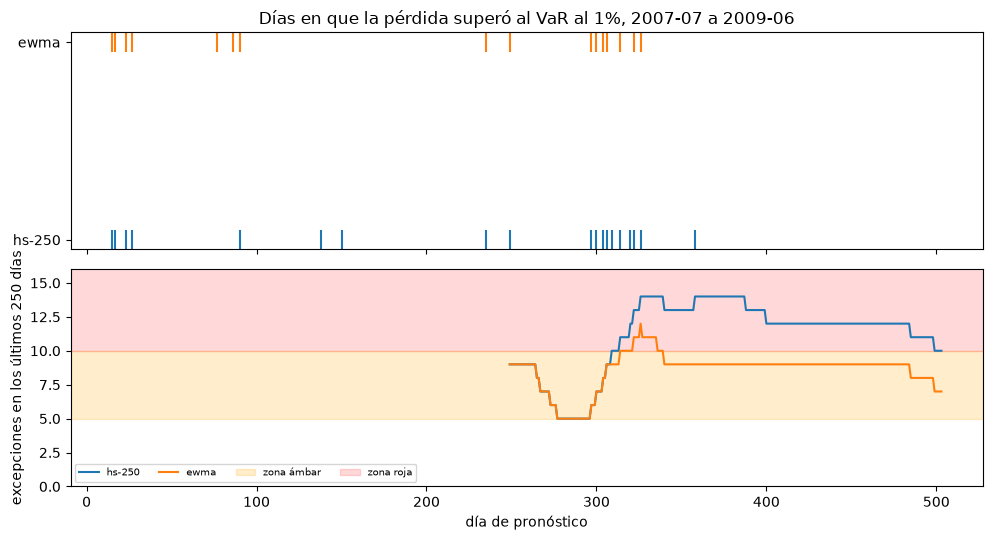

In [11]:
# Contar los modelos en rojo en cobertura, independencia y duración en cada ventana de crisis y nivel, y dibujar las excepciones de 2007-09
labels = {"market.kupiec_pof": "cobertura (Kupiec)", "market.christoffersen_independence": "independencia", "market.duration_test": "duración"}
print(f"{'ventana':15s} {'nivel':>6s}  " + "  ".join(f"{name:>18s}" for name in labels.values()) + "   modelos")
for window in ("equity-2007-09", "equity-2020", "rates-2022"):
    for alpha in (0.01, 0.025):
        rows = [t for t in windows[window]["tests"] if t["segment"] == f"alpha={alpha:g}"]
        reds = [sum(t["light"] == "red" for t in rows if t["test_id"] == test_id) for test_id in labels]
        print(f"{window:15s} {alpha:6.3f}  " + "  ".join(f"{r:18d}" for r in reds) + f"   {len({t['model_id'] for t in rows})}")

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
for position, model_id in enumerate(("hs-250", "ewma")):
    flags, var, rows = series_of("equity-2007-09", model_id, 0.01)
    top.scatter(np.flatnonzero(flags), np.full(int(flags.sum()), position), marker="|", s=200, label=model_id)
top.set_yticks([0, 1])
top.set_yticklabels(["hs-250", "ewma"])
top.set_title("Días en que la pérdida superó al VaR al 1%, 2007-07 a 2009-06")
for model_id, counts in rolling.items():
    bottom.plot(np.arange(counts.size) + 249, counts, label=model_id)
bottom.axhspan(5, 10, color="orange", alpha=0.2, label="zona ámbar")
bottom.axhspan(10, 20, color="red", alpha=0.15, label="zona roja")
bottom.set_ylim(0, 16)
bottom.set_xlabel("día de pronóstico")
bottom.set_ylabel("excepciones en los últimos 250 días")
bottom.legend(fontsize=7, ncol=4)
fig.tight_layout()
plt.show()

## Resultados

- **Kupiec, a mano y con el motor.** `hs-250` en la crisis superó su VaR al 1 por ciento 19 veces en 504 días contra 5,04 esperadas. La razón de verosimilitud es 22,9015 con un valor p asintótico de 1,7e-06 y un valor p binomial exacto de 1,3e-06, y el cálculo a mano, el motor y la fila versionada coinciden en los dígitos impresos.
- **Conteos pequeños.** En una ventana de 250 días al 1 por ciento (2,5 esperadas) cero excepciones dan un valor p asintótico de 0,025, que la compuerta pinta de rojo, mientras que el valor p exacto es 0,189. Con seis excepciones el valor p asintótico es 0,059 (ámbar) y el exacto 0,041, al otro lado de la línea de 0,05. El valor p exacto es el que hay que leer cuando el conteo esperado es menor que unos diez.
- **Independencia.** Para `garch-t` en la crisis al 2,5 por ciento hay 31 días de excepción y ninguno fue seguido por otro al día siguiente: $\pi_{11} = 0$ frente a $\pi_{01} = 0,0657$. $LR_{ind}$ es 4,0750 (p 0,0435, rojo) y $LR_{cc} = 19,7157 + 4,0750 = 23,7907$. Aquí el rechazo viene de excepciones que nunca caen en días consecutivos, no de un agrupamiento de días adyacentes; la prueba de independencia mira solo un paso adelante.
- **Duración.** Las 19 excepciones de `hs-250` dejan 18 intervalos completos con una media de 19,1 días donde la nula espera 100, y muchos intervalos de 2 a 6 días. La forma de Weibull es 0,690 (bajo 1: riesgo instantáneo decreciente, agrupamiento), $LR$ 5,1768 y el valor p de Monte Carlo 0,0824, ámbar. El mismo modelo tiene un valor p de cobertura de 1,7e-06 y está solo en ámbar en duración: las pruebas responden preguntas distintas.
- **Cuantil dinámico.** La forma cuadrática calculada desde su definición es 121,1612 con rango 6, igual a la del motor; el valor p de Monte Carlo es 0,0003 y el asintótico se redondea a 0,0000 con cuatro decimales.
- **El semáforo.** Hasta 4 excepciones en 250 días la probabilidad acumulada está bajo 95 por ciento (89,22 por ciento en 4) y la zona es verde con multiplicador 1,50; 5 a 9 excepciones son ámbar (95,88 por ciento en 5, 99,97 por ciento en 9) con multiplicadores de 1,70 a 1,92; desde 10 (99,9946 por ciento) la zona es roja con multiplicador 2,00. En las 255 ventanas móviles de la crisis `hs-250` estuvo en ámbar en 60 y en rojo en 195, con un máximo de 14 excepciones y una última ventana de 10 (rojo, 2,00), y `ewma` estuvo en ámbar en 229 y en rojo en 26, con un máximo de 12 y una última ventana de 7 (ámbar, 1,83). Los recuentos versionados son idénticos.
- **La batería se reproduce.** Las 30 filas versionadas (`hs-250`, ambos niveles, tres ventanas de crisis, cinco pruebas) vuelven con una diferencia máxima de 5e-07 (los nueve dígitos significativos que guarda el archivo) y ninguna luz que difiera, aunque las filas versionadas se calcularon con el motor 0.7.0 y el cuaderno corre el 0.8.1.
- **Qué ve cada prueba.** En la crisis 17 de 17 modelos están en rojo en Kupiec en ambos niveles. La independencia está en rojo para ninguno al 1 por ciento y para 4 al 2,5 por ciento; la duración para 2 y 4. En `equity-2020` Kupiec está en rojo para 12 y 11 modelos y la independencia para ninguno; en `rates-2022` Kupiec está en rojo para 7 y 12 modelos, la independencia para ninguno y la duración para 1 y 3. En estas ventanas la falla dominante es el **número** de excepciones, y el agrupamiento a los rezagos que ven estas pruebas es la secundaria.

Lo que este cuaderno no muestra: si la pérdida esperada es correcta (cuaderno 04) ni cuál de los modelos que pasan las compuertas es el mejor (cuaderno 05).

## Resumen

- Cada prueba de la batería lee las banderas de excepción: una ventana cuyos retornos se retienen por licencia se puede someter a backtest desde sus días de excepción guardados, y las filas versionadas vuelven exactamente desde ellos.
- Kupiec contrasta el conteo, la independencia y la cobertura condicional de Christoffersen contrastan el orden, la prueba de duración mira los intervalos y la de cuantil dinámico pregunta si los aciertos se pueden predecir. Un modelo puede pasar una y fallar otra, así que la batería las informa por separado.
- Con 2,5 excepciones esperadas el valor p asintótico es mala guía; lee el binomial exacto a su lado. Lo mismo vale para los valores p de Monte Carlo de las pruebas de duración y de cuantil dinámico, que el motor usa para la luz.
- El semáforo de Basilea es una probabilidad binomial acumulada cortada en 95 y 99,99 por ciento, con un multiplicador que sube por zona; se puede calcular en cada ventana móvil, y el recuento versionado coincide.
- Las luces de la batería de mercado del motor son compuertas internas, no umbrales regulatorios; solo las zonas y los multiplicadores del semáforo son el texto del marco.

**Qué probar después.** Vuelve a correr el paso 7 con otros modelos de la escalera y con `alpha = 0.025`, y busca una ventana y un modelo para los que la prueba de independencia esté en rojo mientras Kupiec está en verde; luego continúa con el cuaderno 04, que prueba la propia pérdida esperada.

## Referencias

- Kupiec, P. H. (1995), Techniques for verifying the accuracy of risk measurement models, Journal of Derivatives 3(2). https://doi.org/10.3905/jod.1995.407942
- Christoffersen, P. F. (1998), Evaluating interval forecasts, International Economic Review 39(4). https://doi.org/10.2307/2527341
- Christoffersen, P. y Pelletier, D. (2004), Backtesting value-at-risk: a duration-based approach, Journal of Financial Econometrics 2(1). https://doi.org/10.1093/jjfinec/nbh004
- Engle, R. F. y Manganelli, S. (2004), CAViaR: conditional autoregressive value at risk by regression quantiles, Journal of Business and Economic Statistics 22(4). https://doi.org/10.1198/073500104000000370
- Comité de Supervisión Bancaria de Basilea (1996), Supervisory framework for the use of backtesting in conjunction with the internal models approach to market risk capital requirements. https://www.bis.org/publ/bcbs22.htm
- Marco de Basilea, MAR32.9 Tabla 1 (el multiplicador) y MAR99 (el diseño de las zonas), tal como los implementa `riskvalidation.market.frtb` del motor.